# CODA benchmarks

`bash setup.sh` · Jupyter kernel: **CODA**

| Вариант | Реализация |
|---|---|
| cuBLAS / PyTorch eager | Наивная композиция операций из testing.py |
| cuBLAS + torch.compile | Та же композиция; база speedup = 1× |
| CODA (Triton, project) | Ваши GemmResRmsGemm2, GemmRope, GemmCE |
| Liger | Библиотечный RMSNorm/RoPE/CE + GEMM PyTorch |
| Liger fused CE | Fused linear CE; только fwd при произвольном upstream gradient |
| FlashInfer | Библиотечный RMSNorm/RoPE + GEMM PyTorch; только fwd |
| QuACK | QuACK GEMM с autograd + эпилог PyTorch |

Для каждого метода выбирается одна версия: с torch.compile, если компиляция работает в данном режиме, иначе без него. Наивный и compiled PyTorch показаны отдельно. CUDA выбирается автоматически; без неё выполняются только два CPU smoke-теста.

Версии из [CODA, C.2](https://arxiv.org/html/2605.19269v1#A3.SS2): PyTorch 2.10.0, CuTeDSL 4.4.2, Liger 0.8.0, FlashInfer 0.6.10.post1, QuACK 0.4.1.

Бенчмаркинг блоков проекта, включая вспомогательные редукции, оформлен как [Figure 11](https://arxiv.org/html/2605.19269v1#S4.F11). В каждой ячейке — один эксперимент. После целевых GPU-прогонов строится общая сетка: строки — блоки, столбцы — Forward / Backward / Forward + Backward, группы столбиков — hidden size `d`. `CODA (Triton, project)` обозначает ваши ядра.


In [1]:
import math
from pathlib import Path
from datetime import datetime
from importlib.metadata import version, PackageNotFoundError
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bench import benchmark
from testing import (reference_gemm_res_rms_gemm, reference_gemm_rope, reference_gemm_CE,
                     precompute_rope_cache, coda_rms, coda_rope, coda_ce,
                     liger_rms, liger_rope, liger_ce, liger_ce_unfused, flashinfer_rms, flashinfer_rope,
                     quack_rms, quack_rope, quack_ce, prepare_backend)

torch.set_num_threads(1)
torch._dynamo.config.recompile_limit = 64
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cuda.matmul.allow_bf16_reduced_precision_reduction = False
torch.backends.cudnn.allow_tf32 = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TRACE = False
results = []
required = {'torch': '2.10.0', 'nvidia-cutlass-dsl': '4.4.2', 'liger-kernel': '0.8.0',
            'flashinfer-python': '0.6.10.post1', 'quack-kernels': '0.4.1'}
versions = {}
for package, expected in required.items():
    try:
        versions[package] = version(package)
    except PackageNotFoundError:
        versions[package] = 'not installed'
    if DEVICE == 'cuda' or package == 'torch':
        assert versions[package].split('+')[0] == expected, f'{package}: {versions[package]} != {expected}; run bash setup.sh'
hardware = torch.cuda.get_device_name() if DEVICE == 'cuda' else 'CPU'
print(versions)
print(hardware)


{'torch': '2.10.0+cu128', 'nvidia-cutlass-dsl': '4.4.2', 'liger-kernel': '0.8.0', 'flashinfer-python': '0.6.10.post1', 'quack-kernels': '0.4.1'}
NVIDIA H100 80GB HBM3


In [2]:
references = {'rms': reference_gemm_res_rms_gemm, 'rope': reference_gemm_rope, 'ce': reference_gemm_CE}
compiled = {task: torch.compile(fn, fullgraph=True, dynamic=False, options={"emulate_precision_casts": True}) for task, fn in references.items()}
gpu_variants = {
    'rms': [('cuBLAS', references['rms']), ('cuBLAS + torch.compile', compiled['rms']),
            ('CODA (Triton, project)', coda_rms), ('Liger', liger_rms),
            ('FlashInfer', flashinfer_rms), ('QuACK', quack_rms)],
    'rope': [('cuBLAS', references['rope']), ('cuBLAS + torch.compile', compiled['rope']),
             ('CODA (Triton, project)', coda_rope), ('Liger', liger_rope),
             ('FlashInfer', flashinfer_rope), ('QuACK', quack_rope)],
    'ce': [('cuBLAS', references['ce']), ('cuBLAS + torch.compile', compiled['ce']),
           ('CODA (Triton, project)', coda_ce), ('Liger', liger_ce_unfused),
           ('Liger fused CE', liger_ce), ('QuACK', quack_ce)],
}

def plot_speedups(frame):
    from ast import literal_eval
    titles = {'rms': 'GEMM-Residual-RMS-GEMM', 'rope': 'GEMM-RoPE-GEMM', 'ce': 'GEMM-CrossEntropy'}
    modes = {'fwd': 'Forward', 'bwd': 'Backward', 'fwd+bwd': 'Forward + Backward'}
    palette = {'CODA': '#eb5e28', 'Liger': '#403d39', 'FlashInfer': '#ccc5b9', 'QuACK': '#007c9c'}
    valid = frame[(frame.status == 'ok') & ~frame.implementation.isin(('cuBLAS + torch.compile', 'PyTorch + torch.compile (baseline)'))].dropna(subset=['speedup_compile'])
    for (device, dtype), data in valid.groupby(['device', 'dtype'], sort=False):
        tasks = [task for task in titles if task in data.task.values]
        selected_modes = [mode for mode in modes if mode in data['mode'].values]
        fig, axes = plt.subplots(len(tasks), len(selected_modes), squeeze=False,
                                 figsize=(5 * len(selected_modes), 3.7 * len(tasks)))
        for i, task in enumerate(tasks):
            for j, mode in enumerate(selected_modes):
                ax = axes[i, j]
                panel = data[(data.task == task) & (data['mode'] == mode)]
                cases, names = panel['shape'].unique(), panel.implementation.unique()
                if not len(cases):
                    ax.set_visible(False)
                    continue
                width = 0.8 / len(names)
                for k, name in enumerate(names):
                    rows = panel[panel.implementation == name].set_index('shape').reindex(cases)
                    color = next((color for prefix, color in palette.items() if name.startswith(prefix)), '#e2ddd5')
                    ax.bar([x + (k - (len(names) - 1) / 2) * width for x in range(len(cases))],
                           rows.speedup_compile, width, yerr=rows.speedup_compile * rows.std_ms / rows.mean_ms,
                           color=color, edgecolor='black', linewidth=1.2, label=name,
                           error_kw={'ecolor': 'black', 'elinewidth': 1.5})
                ax.axhline(1, color='#808080', linestyle='--', linewidth=1.8, label='compiled PyTorch (1×)')
                labels = [f'd={literal_eval(case)[2]}' for case in cases]
                if len(set(labels)) != len(labels):
                    labels = [f'd={literal_eval(case)[2]}, M={literal_eval(case)[1]}' for case in cases]
                ax.set(xticks=range(len(cases)), xticklabels=labels, ylabel='Speedup' if j == 0 else '',
                       title=f'{titles[task]}\n{modes[mode]}')
                ax.tick_params(axis='x', labelrotation=45, direction='out')
                errors = panel.speedup_compile * panel.std_ms / panel.mean_ms
                ax.set_ylim(max(0, min(0.8, (panel.speedup_compile - errors).min() - 0.03)),
                            max(1.2, (panel.speedup_compile + errors).max() * 1.08))
        handles = {}
        for ax in axes.flat:
            h, labels = ax.get_legend_handles_labels()
            handles.update(zip(labels, h))
        fig.legend(handles.values(), handles.keys(), loc='upper center', ncol=min(4, len(handles)), frameon=False, fontsize=9)
        caption = f'{device} · {dtype} · speedup / compiled PyTorch'
        if len(frame['shape'].unique()) == 1:
            caption += f" · (B, M, N, K, K2)={frame['shape'].iloc[0]}"
        fig.text(0.5, 0.01, caption, ha='center', fontsize=9)
        fig.tight_layout(rect=(0, 0.06, 1, 0.86 if len(tasks) == 1 else 0.93))
        plt.show()


def make_inputs(task, shape, device, dtype, eps=1e-6):
    torch.manual_seed(0)
    B, M, N, K, K2 = shape
    def rand(shape, scale=1):
        return (torch.randn(shape, device=device, dtype=dtype) * scale).requires_grad_()
    x, w = rand((B, M, N)), rand((N, K), N**-0.5)
    if task == 'ce':
        return x, w, torch.randint(K, (B, M), device=device)
    w2 = rand((K, K2), K**-0.5)
    if task == 'rms':
        return x, w, rand((B, M, K)), rand((K,)), w2, eps
    H = math.gcd(K, 128)
    cos, sin = precompute_rope_cache(M, H, device=device, dtype=dtype)
    return x, w, cos.repeat(1, K // H), sin.repeat(1, K // H), w2


def experiment(task, shape, mode, *, device=None, dtype=torch.float32, eps=1e-6, names=None, trace_dir=None):
    device = device or DEVICE
    if device == 'cuda' and DEVICE != 'cuda':
        return
    variants = gpu_variants[task] if device == 'cuda' else [('PyTorch eager (baseline)', references[task]), ('PyTorch + torch.compile (baseline)', compiled[task])]
    if names is not None:
        variants = [(name, fn) for name, fn in variants if name in names]
    args = make_inputs(task, shape, device, dtype, eps)
    prepared = []
    for name, fn in variants:
        fn = prepare_backend(fn, args)
        if name not in ('cuBLAS', 'cuBLAS + torch.compile', 'PyTorch eager (baseline)', 'PyTorch + torch.compile (baseline)'):
            fn.compiled = torch.compile(fn, fullgraph=True, dynamic=False, options={"emulate_precision_casts": True})
        prepared.append((name, fn))
    frame = benchmark(prepared, args, mode=mode,
                      warmup=10 if device == 'cuda' else 2, repeats=30 if device == 'cuda' else 3, trace_dir=trace_dir)
    frame['task'], frame['shape'], frame['eps'] = task, str(shape), eps
    frame['packages'], frame['threads'], frame['hardware'] = str(versions), torch.get_num_threads(), hardware
    results.append(frame)
    if 'compile_fallback' in frame:
        for row in frame[frame.compile_fallback.notna()].itertuples():
            print(f'{row.implementation}: torch.compile unavailable in {mode}; measuring eager')
    for row in frame[frame.status != 'ok'].itertuples():
        print(f'{row.implementation}: {row.reason}')
    frame['ms'] = [f'{m:.2g} ± {s:.1g}' for m, s in zip(frame.mean_ms, frame.std_ms)]
    display(frame.loc[frame.status == 'ok', ['implementation', 'ms', 'speedup_compile']].style
            .format({'speedup_compile': '{:.2f}×'}).hide(axis='index'))
    plot_speedups(frame)
    assert not (frame.status == 'incorrect').any(), frame.loc[frame.status == 'incorrect', 'reason'].tolist()


def check_rms():
    if DEVICE != 'cuda':
        return
    from coda import GemmResRmsGemm, GemmResRmsGemm2
    for dtype in (torch.float32, torch.bfloat16):
        atol, rtol = (1e-5, 1e-4) if dtype == torch.float32 else (1e-2, 1e-2)
        for cls in (GemmResRmsGemm, GemmResRmsGemm2):
            for eps in (None, 0.1):
                args = make_inputs('rms', (2, 131, 19, 38, 17), 'cuda', dtype)
                args = args[:-1] if eps is None else (*args[:-1], eps)
                out, ref = cls.apply(*args), references['rms'](*args)
                torch.testing.assert_close(out, ref, atol=atol, rtol=rtol)
                grad = torch.randn(2, 17, 131, device='cuda', dtype=dtype).transpose(1, 2)
                inputs = tuple(x for x in args if isinstance(x, torch.Tensor) and x.requires_grad)
                for a, b in zip(torch.autograd.grad(out, inputs, grad), torch.autograd.grad(ref, inputs, grad)):
                    torch.testing.assert_close(a, b, atol=atol, rtol=rtol)


## Smoke tests · CPU / CUDA

/root/coda-bench/.venv/lib/python3.12/site-packages/torch/_dynamo/variables/functions.py:2056: UserWarning: Dynamo detected a call to a `functools.lru_cache`-wrapped function. Dynamo ignores the cache wrapper and directly traces the wrapped function. Silent incorrectness is only a *potential* risk, not something we have observed. Enable TORCH_LOGS="+dynamo" for a DEBUG stack trace.
  torch._dynamo.utils.warn_once(msg)


FlashInfer: torch.compile unavailable in fwd; measuring eager
QuACK: torch.compile unavailable in fwd; measuring eager
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.056 ± 0.006,1.37×
cuBLAS + torch.compile,0.077 ± 0.005,1.00×
"CODA (Triton, project) + torch.compile",0.26 ± 0.004,0.29×
Liger + torch.compile,0.093 ± 0.006,0.83×
FlashInfer,0.062 ± 0.004,1.25×


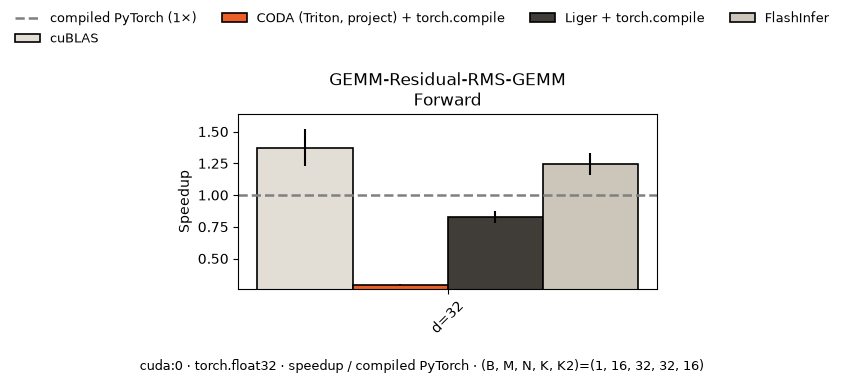

In [3]:
experiment('rms', (1, 16, 32, 32, 16), 'fwd')

Liger: torch.compile unavailable in fwd+bwd; measuring eager
QuACK: torch.compile unavailable in fwd+bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.3 ± 0.006,1.36×
cuBLAS + torch.compile,0.4 ± 0.01,1.00×
"CODA (Triton, project) + torch.compile",0.31 ± 0.01,1.30×
Liger,0.45 ± 0.009,0.90×


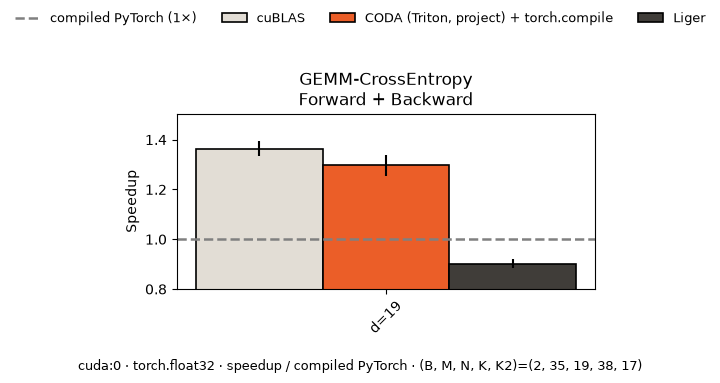

In [4]:
experiment('ce', (2, 35, 19, 38, 17), 'fwd+bwd')

## GPU · FP32 · correctness

### GEMM + residual + RMSNorm + GEMM

/root/coda-bench/.venv/lib/python3.12/site-packages/torch/_inductor/compile_fx.py:321: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(


FlashInfer: torch.compile unavailable in fwd; measuring eager
QuACK: torch.compile unavailable in fwd; measuring eager
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.068 ± 0.004,1.26×
cuBLAS + torch.compile,0.086 ± 0.004,1.00×
"CODA (Triton, project) + torch.compile",0.33 ± 0.005,0.26×
Liger + torch.compile,0.11 ± 0.006,0.81×
FlashInfer,0.071 ± 0.004,1.20×


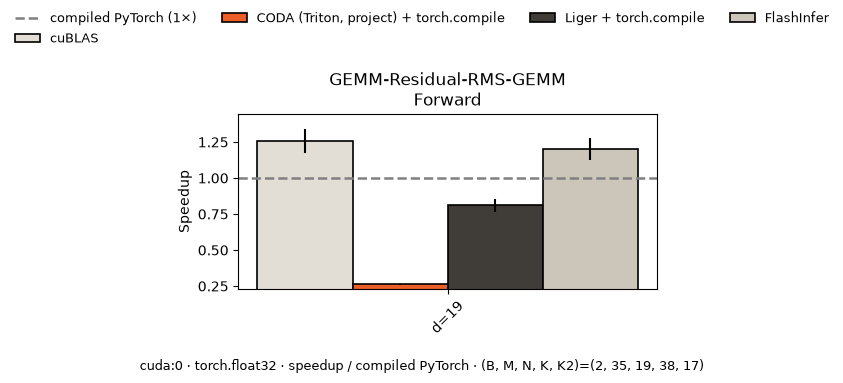

In [5]:
experiment('rms', (2, 35, 19, 38, 17), 'fwd', device='cuda')

QuACK: torch.compile unavailable in bwd; measuring eager
FlashInfer: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.2 ± 0.007,1.34×
cuBLAS + torch.compile,0.27 ± 0.007,1.00×
"CODA (Triton, project) + torch.compile",0.29 ± 0.008,0.95×
Liger + torch.compile,0.29 ± 0.007,0.93×


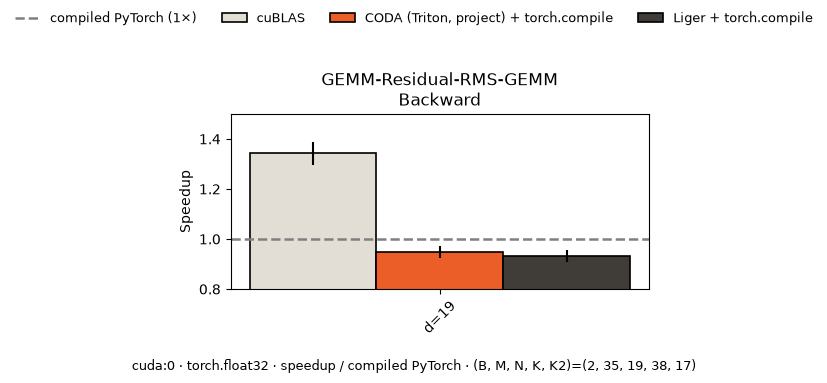

In [6]:
experiment('rms', (2, 35, 19, 38, 17), 'bwd', device='cuda')

QuACK: torch.compile unavailable in fwd+bwd; measuring eager
FlashInfer: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.33 ± 0.009,1.40×
cuBLAS + torch.compile,0.46 ± 0.01,1.00×
"CODA (Triton, project) + torch.compile",0.45 ± 0.01,1.02×
Liger + torch.compile,0.51 ± 0.03,0.90×


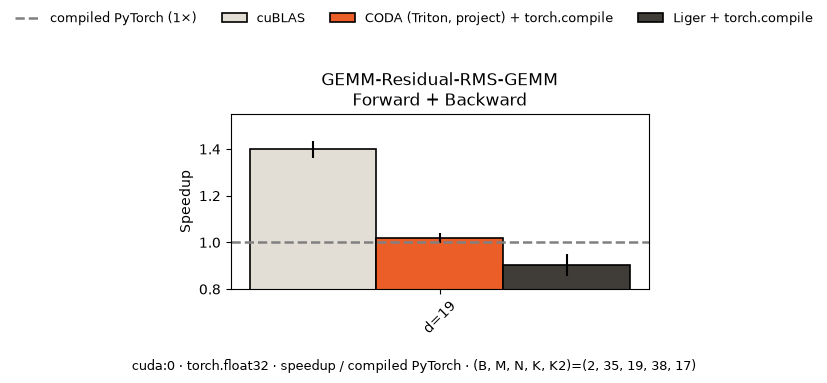

In [7]:
experiment('rms', (2, 35, 19, 38, 17), 'fwd+bwd', device='cuda')

### GEMM + RoPE + GEMM

FlashInfer: torch.compile unavailable in fwd; measuring eager
QuACK: torch.compile unavailable in fwd; measuring eager
FlashInfer: NotImplementedError: FlashInfer RoPE requires FP16/BF16 inputs
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.11 ± 0.007,0.77×
cuBLAS + torch.compile,0.088 ± 0.008,1.00×
"CODA (Triton, project) + torch.compile",0.057 ± 0.005,1.56×
Liger + torch.compile,0.12 ± 0.005,0.73×


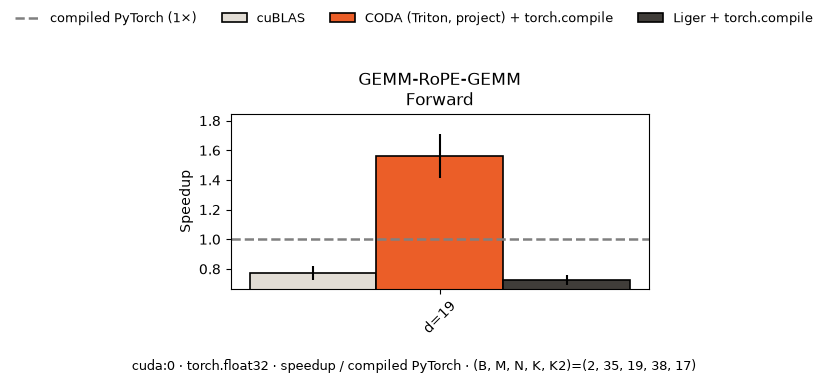

In [3]:
experiment('rope', (2, 35, 19, 38, 17), 'fwd', device='cuda')

QuACK: torch.compile unavailable in bwd; measuring eager
FlashInfer: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.3 ± 0.006,0.64×
cuBLAS + torch.compile,0.19 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",0.18 ± 0.005,1.09×
Liger + torch.compile,0.23 ± 0.007,0.85×


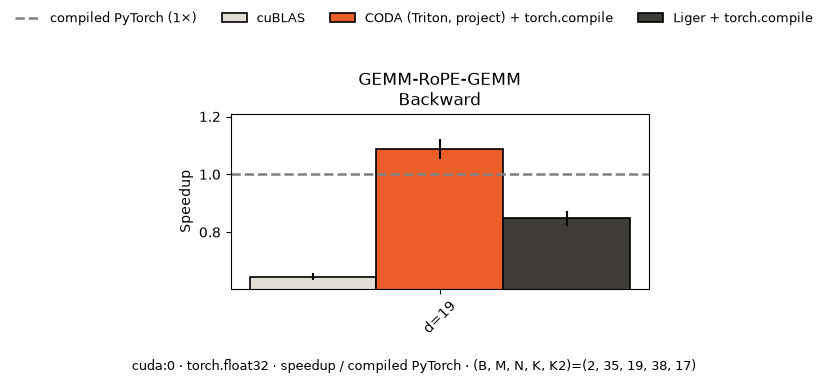

In [9]:
experiment('rope', (2, 35, 19, 38, 17), 'bwd', device='cuda')

QuACK: torch.compile unavailable in fwd+bwd; measuring eager
FlashInfer: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.48 ± 0.007,0.75×
cuBLAS + torch.compile,0.36 ± 0.009,1.00×
"CODA (Triton, project) + torch.compile",0.32 ± 0.006,1.13×
Liger + torch.compile,0.43 ± 0.03,0.84×


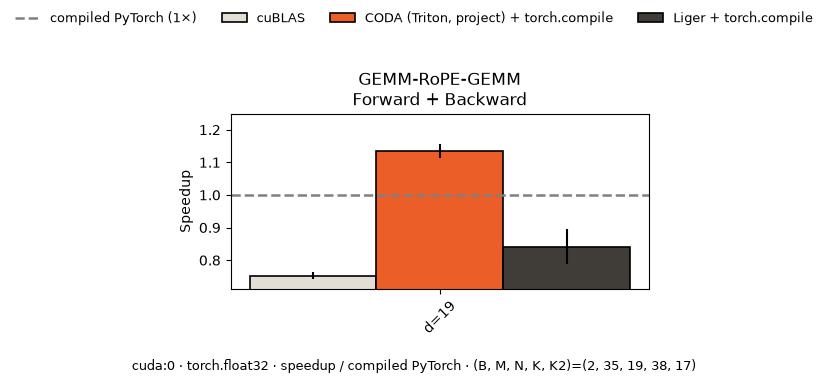

In [10]:
experiment('rope', (2, 35, 19, 38, 17), 'fwd+bwd', device='cuda')

### GEMM + cross entropy

Liger: torch.compile unavailable in fwd; measuring eager
QuACK: torch.compile unavailable in fwd; measuring eager
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.064 ± 0.004,1.17×
cuBLAS + torch.compile,0.074 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",0.06 ± 0.007,1.24×
Liger,0.24 ± 0.008,0.31×
Liger fused CE + torch.compile,0.17 ± 0.006,0.43×


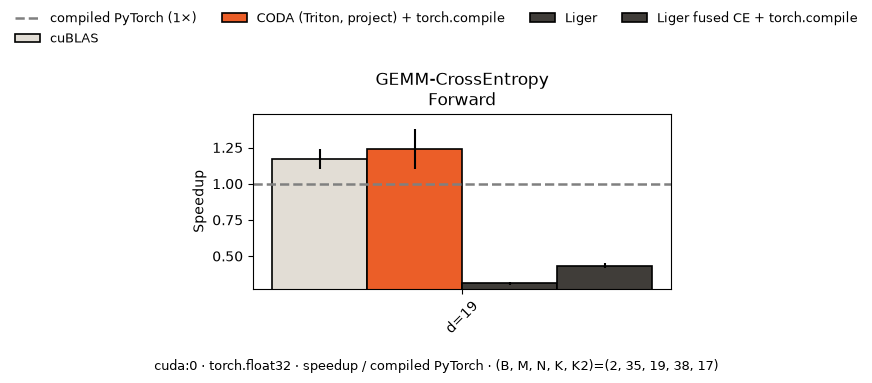

In [11]:
experiment('ce', (2, 35, 19, 38, 17), 'fwd', device='cuda')

Liger: torch.compile unavailable in bwd; measuring eager
QuACK: torch.compile unavailable in bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.16 ± 0.004,1.07×
cuBLAS + torch.compile,0.17 ± 0.005,1.00×
"CODA (Triton, project) + torch.compile",0.16 ± 0.004,1.05×
Liger,0.18 ± 0.02,0.92×


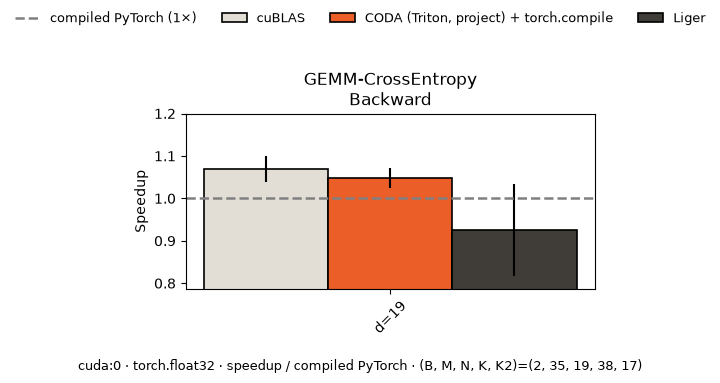

In [12]:
experiment('ce', (2, 35, 19, 38, 17), 'bwd', device='cuda')

Liger: torch.compile unavailable in fwd+bwd; measuring eager
QuACK: torch.compile unavailable in fwd+bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only
QuACK: NotImplementedError: QuACK requires FP16/BF16 inputs


implementation,ms,speedup_compile
cuBLAS,0.26 ± 0.005,1.26×
cuBLAS + torch.compile,0.32 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",0.3 ± 0.007,1.08×
Liger,0.45 ± 0.03,0.71×


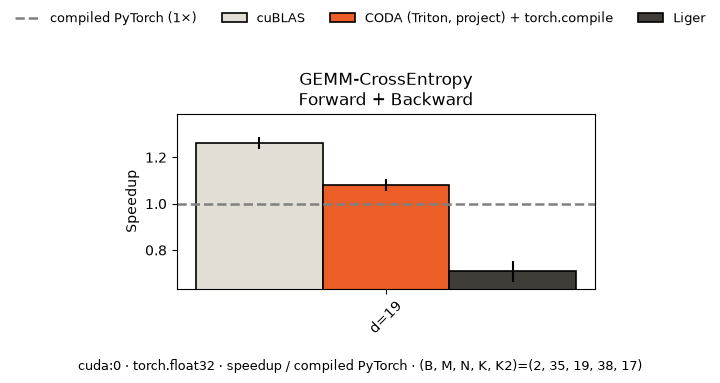

In [13]:
experiment('ce', (2, 35, 19, 38, 17), 'fwd+bwd', device='cuda')

In [14]:
check_rms()

## GPU · BF16 · small correctness checks

FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,0.09 ± 0.008,0.96×
cuBLAS + torch.compile,0.087 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",0.069 ± 0.005,1.26×
Liger + torch.compile,0.1 ± 0.006,0.83×
FlashInfer,0.072 ± 0.004,1.22×
QuACK + torch.compile,0.24 ± 0.008,0.37×


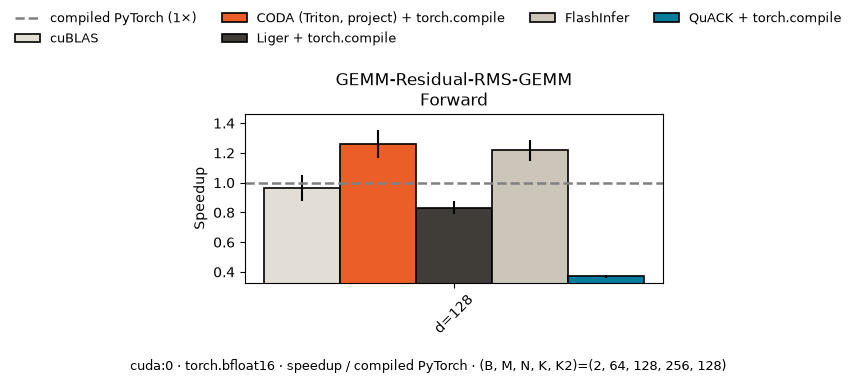

In [15]:
experiment('rms', (2, 64, 128, 256, 128), 'fwd', device='cuda', dtype=torch.bfloat16)

/root/coda-bench/.venv/lib/python3.12/site-packages/torch/_dynamo/variables/functions.py:1946: UserWarning: Dynamo does not know how to trace the builtin `posix.stat.` This function is either a Python builtin (e.g. _warnings.warn) or a third-party C/C++ Python extension (perhaps created with pybind).
If it is a Python builtin, please file an issue on GitHub so the PyTorch team can add support for it and see the next case for a workaround.
If it is a third-party C/C++ Python extension, please either wrap it into a PyTorch-understood custom operator (see https://pytorch.org/tutorials/advanced/custom_ops_landing_page.html for more details) or, if it is traceable, use `torch.compiler.allow_in_graph`.
  torch._dynamo.utils.warn_once(explanation + "\n" + "\n".join(hints))


FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,0.15 ± 0.009,0.59×
cuBLAS + torch.compile,0.087 ± 0.004,1.00×
"CODA (Triton, project) + torch.compile",0.055 ± 0.004,1.58×
Liger + torch.compile,0.12 ± 0.005,0.71×
FlashInfer,0.082 ± 0.006,1.06×
QuACK + torch.compile,0.23 ± 0.007,0.37×


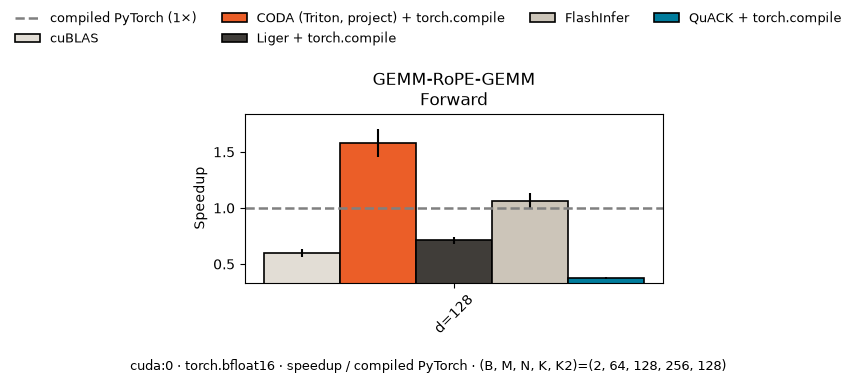

In [16]:
experiment('rope', (2, 64, 128, 256, 128), 'fwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,0.096 ± 0.004,0.78×
cuBLAS + torch.compile,0.075 ± 0.005,1.00×
"CODA (Triton, project) + torch.compile",0.059 ± 0.005,1.27×
Liger,0.25 ± 0.007,0.30×
Liger fused CE + torch.compile,0.25 ± 0.008,0.30×
QuACK + torch.compile,0.16 ± 0.007,0.46×


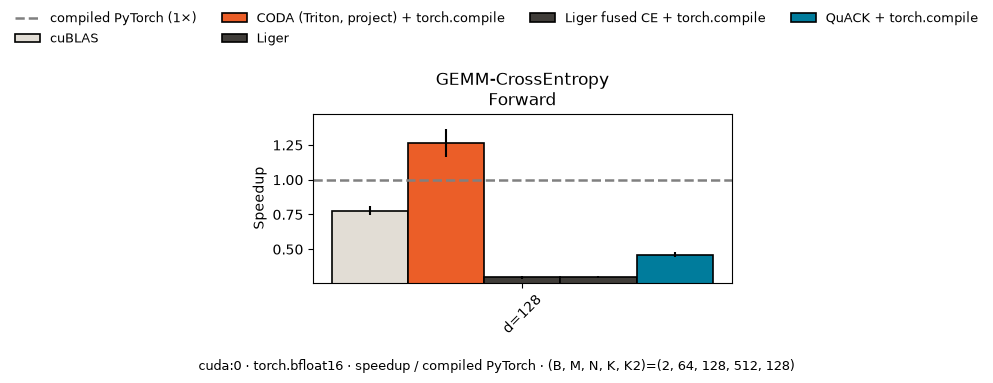

In [17]:
experiment('ce', (2, 64, 128, 512, 128), 'fwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,0.19 ± 0.006,1.00×
cuBLAS + torch.compile,0.19 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",0.21 ± 0.007,0.91×
Liger + torch.compile,0.21 ± 0.006,0.88×
QuACK + torch.compile,0.63 ± 0.02,0.30×


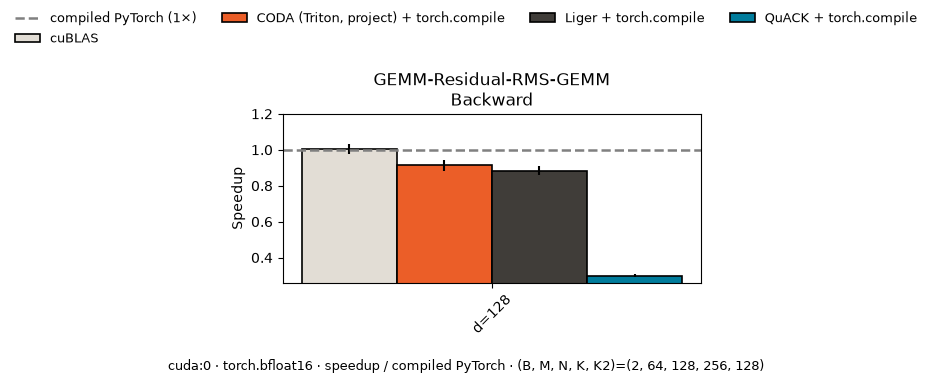

In [18]:
experiment('rms', (2, 64, 128, 256, 128), 'bwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,0.36 ± 0.01,0.52×
cuBLAS + torch.compile,0.19 ± 0.005,1.00×
"CODA (Triton, project) + torch.compile",0.17 ± 0.006,1.12×
Liger + torch.compile,0.21 ± 0.006,0.90×
QuACK + torch.compile,0.51 ± 0.009,0.36×


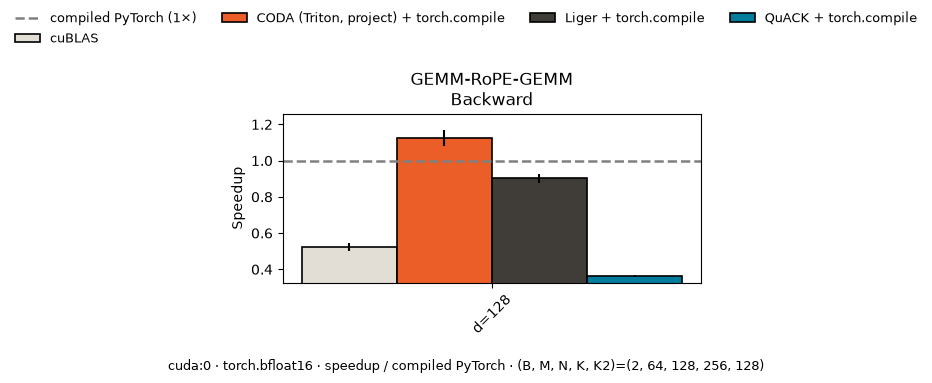

In [19]:
experiment('rope', (2, 64, 128, 256, 128), 'bwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,0.16 ± 0.005,0.95×
cuBLAS + torch.compile,0.15 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",0.16 ± 0.009,0.92×
Liger,0.18 ± 0.007,0.84×
QuACK + torch.compile,0.34 ± 0.01,0.44×


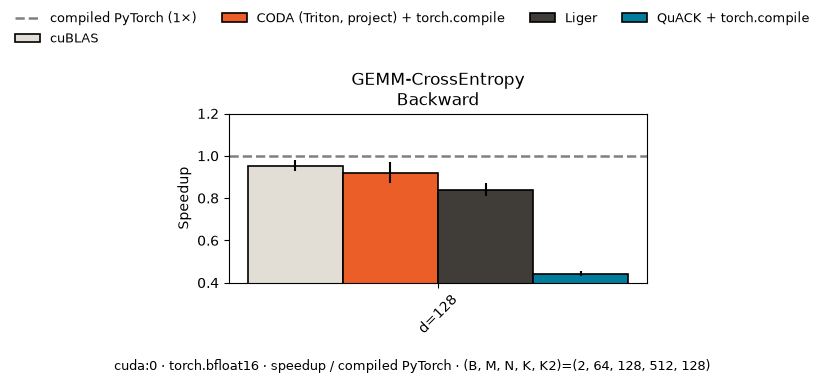

In [20]:
experiment('ce', (2, 64, 128, 512, 128), 'bwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,0.33 ± 0.009,1.07×
cuBLAS + torch.compile,0.35 ± 0.007,1.00×
"CODA (Triton, project) + torch.compile",0.35 ± 0.01,1.02×
Liger + torch.compile,0.45 ± 0.3,0.78×
QuACK + torch.compile,0.85 ± 0.01,0.42×


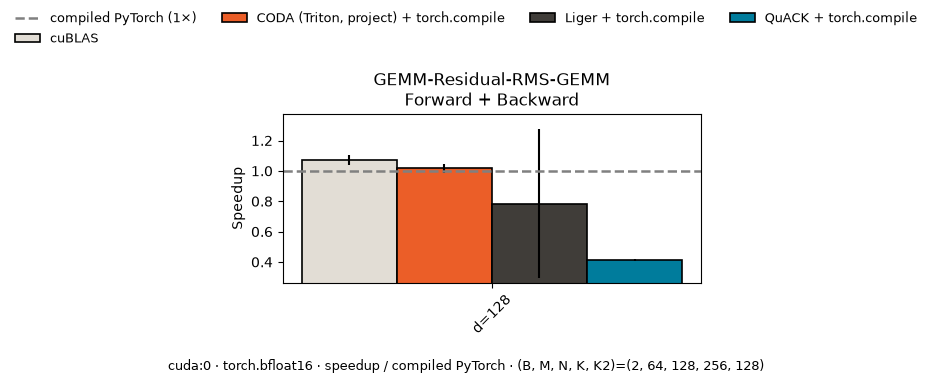

In [21]:
experiment('rms', (2, 64, 128, 256, 128), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,0.53 ± 0.008,0.65×
cuBLAS + torch.compile,0.34 ± 0.008,1.00×
"CODA (Triton, project) + torch.compile",0.31 ± 0.02,1.11×
Liger + torch.compile,0.4 ± 0.007,0.86×
QuACK + torch.compile,0.82 ± 0.01,0.42×


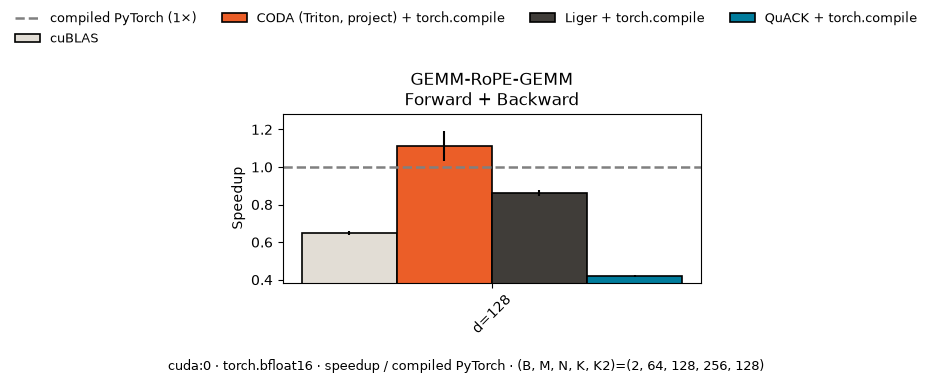

In [22]:
experiment('rope', (2, 64, 128, 256, 128), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in fwd+bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,0.27 ± 0.006,1.12×
cuBLAS + torch.compile,0.31 ± 0.007,1.00×
"CODA (Triton, project) + torch.compile",0.28 ± 0.007,1.08×
Liger,0.47 ± 0.02,0.66×
QuACK + torch.compile,0.58 ± 0.01,0.53×


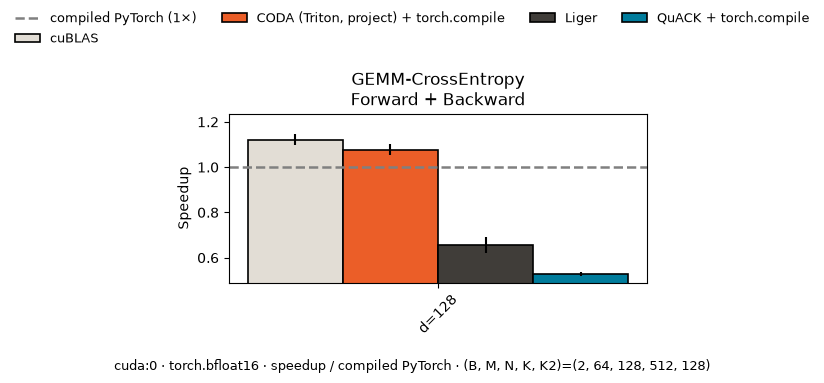

In [23]:
experiment('ce', (2, 64, 128, 512, 128), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

## GPU · BF16

### GEMM + residual + RMSNorm + GEMM

FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,1.1 ± 0.006,0.76×
cuBLAS + torch.compile,0.85 ± 0.006,1.00×
"CODA (Triton, project) + torch.compile",1.6 ± 0.02,0.54×
Liger + torch.compile,0.9 ± 0.008,0.94×
FlashInfer,0.86 ± 0.004,0.99×
QuACK + torch.compile,0.91 ± 0.01,0.93×


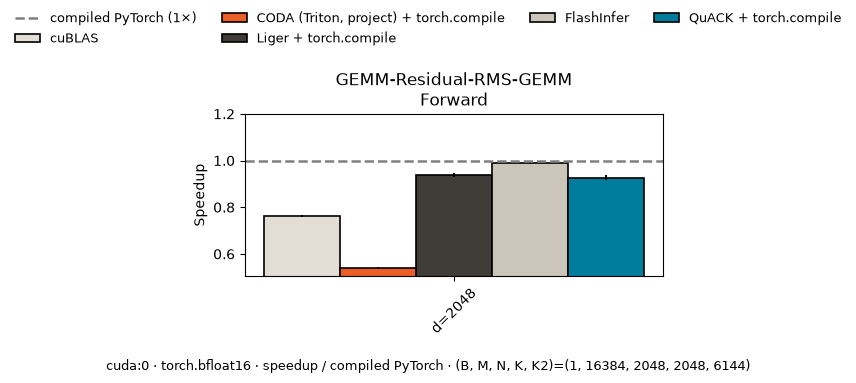

In [24]:
experiment('rms', (1, 16384, 2048, 2048, 6144), 'fwd', device='cuda', dtype=torch.bfloat16)

In [25]:
experiment('rms', (1, 16384, 2048, 2048, 6144), 'bwd', device='cuda', dtype=torch.bfloat16)

cuBLAS + torch.compile: _Mismatch: Tensor-likes are not close!

Mismatched elements: 29 / 4194304 (0.0%)
Greatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)
Greatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)
CODA (Triton, project): _Mismatch: Tensor-likes are not close!

Mismatched elements: 52 / 4194304 (0.0%)
Greatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)
Greatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)
Liger: _Mismatch: Tensor-likes are not close!

Mismatched elements: 81 / 4194304 (0.0%)
Greatest absolute difference: 0.0645751953125 at index (929, 1742) (up to 0.01 allowed)
Greatest relative difference: 2.6582913398742676 at index (929, 1742) (up to 0.01 allowed)
FlashInfer: NotImplementedError: Forward only
QuACK: _Mismatch: Tensor-likes are not close!

Mismatched elements: 29 / 4194304 (0.0%)
Greatest absolute difference: 0.0625 at index (1000

implementation,ms,speedup_compile
cuBLAS,2.1 ± 0.05,nan×


AssertionError: ['_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 29 / 4194304 (0.0%)\nGreatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)\nGreatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 52 / 4194304 (0.0%)\nGreatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)\nGreatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 81 / 4194304 (0.0%)\nGreatest absolute difference: 0.0645751953125 at index (929, 1742) (up to 0.01 allowed)\nGreatest relative difference: 2.6582913398742676 at index (929, 1742) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 29 / 4194304 (0.0%)\nGreatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)\nGreatest relative difference: 10.3057

In [26]:
experiment('rms', (1, 16384, 2048, 2048, 6144), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

cuBLAS + torch.compile: _Mismatch: Tensor-likes are not close!

Mismatched elements: 29 / 4194304 (0.0%)
Greatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)
Greatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)
CODA (Triton, project): _Mismatch: Tensor-likes are not close!

Mismatched elements: 52 / 4194304 (0.0%)
Greatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)
Greatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)
Liger: _Mismatch: Tensor-likes are not close!

Mismatched elements: 81 / 4194304 (0.0%)
Greatest absolute difference: 0.0645751953125 at index (929, 1742) (up to 0.01 allowed)
Greatest relative difference: 2.6582913398742676 at index (929, 1742) (up to 0.01 allowed)
FlashInfer: NotImplementedError: Forward only
QuACK: _Mismatch: Tensor-likes are not close!

Mismatched elements: 29 / 4194304 (0.0%)
Greatest absolute difference: 0.0625 at index (1000

implementation,ms,speedup_compile
cuBLAS,3.2 ± 0.03,nan×


AssertionError: ['_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 29 / 4194304 (0.0%)\nGreatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)\nGreatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 52 / 4194304 (0.0%)\nGreatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)\nGreatest relative difference: 10.305785179138184 at index (528, 924) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 81 / 4194304 (0.0%)\nGreatest absolute difference: 0.0645751953125 at index (929, 1742) (up to 0.01 allowed)\nGreatest relative difference: 2.6582913398742676 at index (929, 1742) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 29 / 4194304 (0.0%)\nGreatest absolute difference: 0.0625 at index (1000, 343) (up to 0.01 allowed)\nGreatest relative difference: 10.3057

FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,3.8 ± 0.1,0.90×
cuBLAS + torch.compile,3.4 ± 0.05,1.00×
"CODA (Triton, project) + torch.compile",5.2 ± 0.03,0.65×
Liger + torch.compile,3.4 ± 0.06,0.99×
FlashInfer,3.4 ± 0.08,1.00×
QuACK + torch.compile,3.3 ± 0.1,1.01×


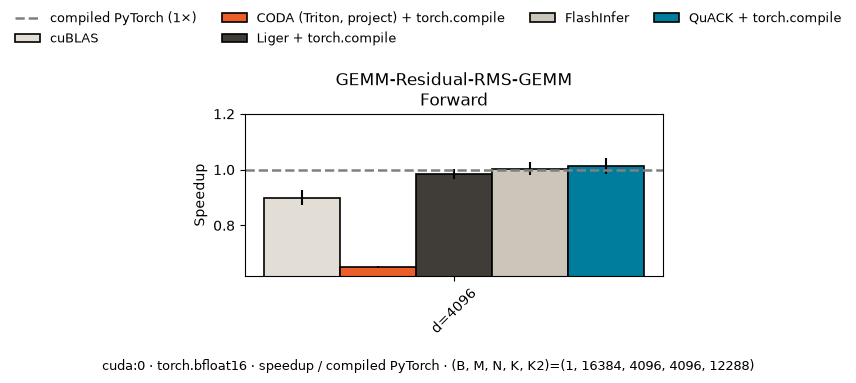

In [27]:
experiment('rms', (1, 16384, 4096, 4096, 12288), 'fwd', device='cuda', dtype=torch.bfloat16)

In [28]:
experiment('rms', (1, 16384, 4096, 4096, 12288), 'bwd', device='cuda', dtype=torch.bfloat16)

cuBLAS + torch.compile: _Mismatch: Tensor-likes are not close!

Mismatched elements: 150 / 16777216 (0.0%)
Greatest absolute difference: 0.0625 at index (9, 2252) (up to 0.01 allowed)
Greatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)
CODA (Triton, project): _Mismatch: Tensor-likes are not close!

Mismatched elements: 357 / 16777216 (0.0%)
Greatest absolute difference: 0.125 at index (3677, 1446) (up to 0.01 allowed)
Greatest relative difference: 37.787879943847656 at index (615, 3327) (up to 0.01 allowed)
Liger: _Mismatch: Tensor-likes are not close!

Mismatched elements: 343 / 16777216 (0.0%)
Greatest absolute difference: 0.125 at index (1129, 2335) (up to 0.01 allowed)
Greatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)
FlashInfer: NotImplementedError: Forward only
QuACK: _Mismatch: Tensor-likes are not close!

Mismatched elements: 150 / 16777216 (0.0%)
Greatest absolute difference: 0.0625 at index (9, 22

implementation,ms,speedup_compile
cuBLAS,7.2 ± 0.09,nan×


AssertionError: ['_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 150 / 16777216 (0.0%)\nGreatest absolute difference: 0.0625 at index (9, 2252) (up to 0.01 allowed)\nGreatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 357 / 16777216 (0.0%)\nGreatest absolute difference: 0.125 at index (3677, 1446) (up to 0.01 allowed)\nGreatest relative difference: 37.787879943847656 at index (615, 3327) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 343 / 16777216 (0.0%)\nGreatest absolute difference: 0.125 at index (1129, 2335) (up to 0.01 allowed)\nGreatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 150 / 16777216 (0.0%)\nGreatest absolute difference: 0.0625 at index (9, 2252) (up to 0.01 allowed)\nGreatest relative difference: 39.0610694

In [29]:
experiment('rms', (1, 16384, 4096, 4096, 12288), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

cuBLAS + torch.compile: _Mismatch: Tensor-likes are not close!

Mismatched elements: 150 / 16777216 (0.0%)
Greatest absolute difference: 0.0625 at index (9, 2252) (up to 0.01 allowed)
Greatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)
CODA (Triton, project): _Mismatch: Tensor-likes are not close!

Mismatched elements: 357 / 16777216 (0.0%)
Greatest absolute difference: 0.125 at index (3677, 1446) (up to 0.01 allowed)
Greatest relative difference: 37.787879943847656 at index (615, 3327) (up to 0.01 allowed)
Liger: _Mismatch: Tensor-likes are not close!

Mismatched elements: 343 / 16777216 (0.0%)
Greatest absolute difference: 0.125 at index (1129, 2335) (up to 0.01 allowed)
Greatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)
FlashInfer: NotImplementedError: Forward only
QuACK: _Mismatch: Tensor-likes are not close!

Mismatched elements: 150 / 16777216 (0.0%)
Greatest absolute difference: 0.0625 at index (9, 22

implementation,ms,speedup_compile
cuBLAS,11 ± 0.1,nan×


AssertionError: ['_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 150 / 16777216 (0.0%)\nGreatest absolute difference: 0.0625 at index (9, 2252) (up to 0.01 allowed)\nGreatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 357 / 16777216 (0.0%)\nGreatest absolute difference: 0.125 at index (3677, 1446) (up to 0.01 allowed)\nGreatest relative difference: 37.787879943847656 at index (615, 3327) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 343 / 16777216 (0.0%)\nGreatest absolute difference: 0.125 at index (1129, 2335) (up to 0.01 allowed)\nGreatest relative difference: 39.06106948852539 at index (2103, 2320) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 150 / 16777216 (0.0%)\nGreatest absolute difference: 0.0625 at index (9, 2252) (up to 0.01 allowed)\nGreatest relative difference: 39.0610694

FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,14 ± 0.08,0.93×
cuBLAS + torch.compile,13 ± 0.09,1.00×
"CODA (Triton, project) + torch.compile",25 ± 1,0.53×
Liger + torch.compile,13 ± 0.08,0.99×
FlashInfer,13 ± 0.04,0.99×
QuACK + torch.compile,13 ± 0.1,1.02×


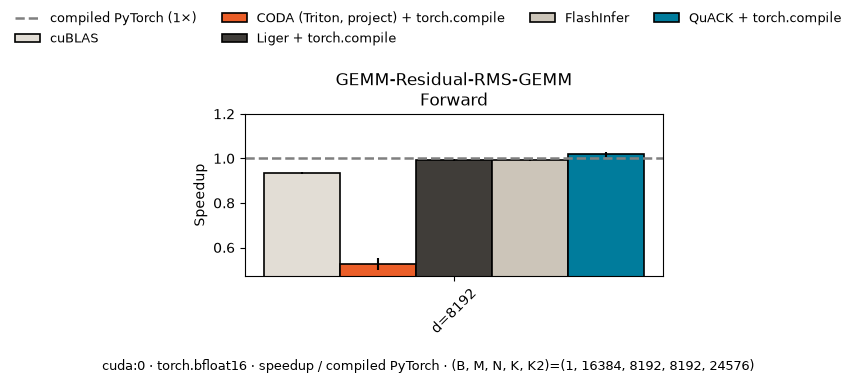

In [30]:
experiment('rms', (1, 16384, 8192, 8192, 24576), 'fwd', device='cuda', dtype=torch.bfloat16)

In [31]:
experiment('rms', (1, 16384, 8192, 8192, 24576), 'bwd', device='cuda', dtype=torch.bfloat16)

cuBLAS + torch.compile: _Mismatch: Tensor-likes are not close!

Mismatched elements: 1004 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)
Greatest relative difference: 9.556962013244629 at index (4200, 1012) (up to 0.01 allowed)
CODA (Triton, project): _Mismatch: Tensor-likes are not close!

Mismatched elements: 1555 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)
Greatest relative difference: 40.8139533996582 at index (6139, 7632) (up to 0.01 allowed)
Liger: _Mismatch: Tensor-likes are not close!

Mismatched elements: 1564 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1314, 7121) (up to 0.01 allowed)
Greatest relative difference: 88.65182495117188 at index (6272, 4452) (up to 0.01 allowed)
FlashInfer: NotImplementedError: Forward only
QuACK: _Mismatch: Tensor-likes are not close!

Mismatched elements: 1004 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1

implementation,ms,speedup_compile
cuBLAS,28 ± 0.6,nan×


AssertionError: ['_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1004 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)\nGreatest relative difference: 9.556962013244629 at index (4200, 1012) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1555 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)\nGreatest relative difference: 40.8139533996582 at index (6139, 7632) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1564 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1314, 7121) (up to 0.01 allowed)\nGreatest relative difference: 88.65182495117188 at index (6272, 4452) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1004 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)\nGreatest relative difference: 9.5

In [32]:
experiment('rms', (1, 16384, 8192, 8192, 24576), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

cuBLAS + torch.compile: _Mismatch: Tensor-likes are not close!

Mismatched elements: 1004 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)
Greatest relative difference: 9.556962013244629 at index (4200, 1012) (up to 0.01 allowed)
CODA (Triton, project): _Mismatch: Tensor-likes are not close!

Mismatched elements: 1555 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)
Greatest relative difference: 40.8139533996582 at index (6139, 7632) (up to 0.01 allowed)
Liger: _Mismatch: Tensor-likes are not close!

Mismatched elements: 1564 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1314, 7121) (up to 0.01 allowed)
Greatest relative difference: 88.65182495117188 at index (6272, 4452) (up to 0.01 allowed)
FlashInfer: NotImplementedError: Forward only
QuACK: _Mismatch: Tensor-likes are not close!

Mismatched elements: 1004 / 67108864 (0.0%)
Greatest absolute difference: 0.125 at index (1

implementation,ms,speedup_compile
cuBLAS,43 ± 0.9,nan×


AssertionError: ['_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1004 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)\nGreatest relative difference: 9.556962013244629 at index (4200, 1012) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1555 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)\nGreatest relative difference: 40.8139533996582 at index (6139, 7632) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1564 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1314, 7121) (up to 0.01 allowed)\nGreatest relative difference: 88.65182495117188 at index (6272, 4452) (up to 0.01 allowed)', '_Mismatch: Tensor-likes are not close!\n\nMismatched elements: 1004 / 67108864 (0.0%)\nGreatest absolute difference: 0.125 at index (1482, 7570) (up to 0.01 allowed)\nGreatest relative difference: 9.5

### GEMM + RoPE + GEMM

FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,2.2 ± 0.007,0.56×
cuBLAS + torch.compile,1.2 ± 0.04,1.00×
"CODA (Triton, project) + torch.compile",2.7 ± 0.02,0.46×
Liger + torch.compile,1.3 ± 0.02,0.93×
FlashInfer,1.2 ± 0.02,1.07×
QuACK + torch.compile,1.3 ± 0.03,0.95×


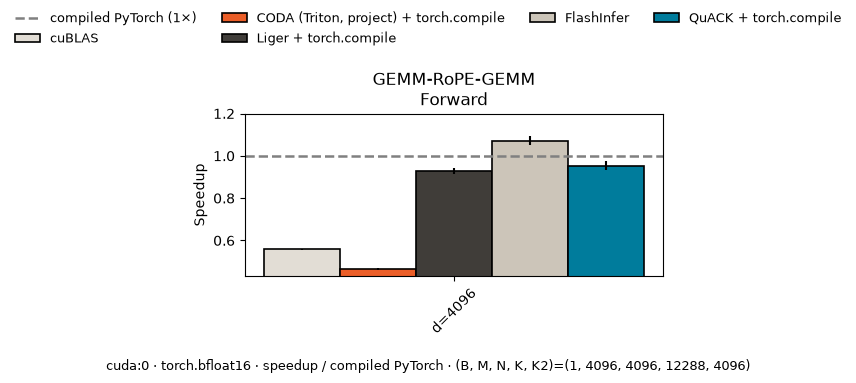

In [33]:
experiment('rope', (1, 4096, 4096, 12288, 4096), 'fwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,3.9 ± 0.04,0.67×
cuBLAS + torch.compile,2.6 ± 0.1,1.00×
"CODA (Triton, project) + torch.compile",3.7 ± 0.04,0.71×
Liger + torch.compile,2.6 ± 0.03,0.99×
QuACK + torch.compile,2.7 ± 0.05,0.96×


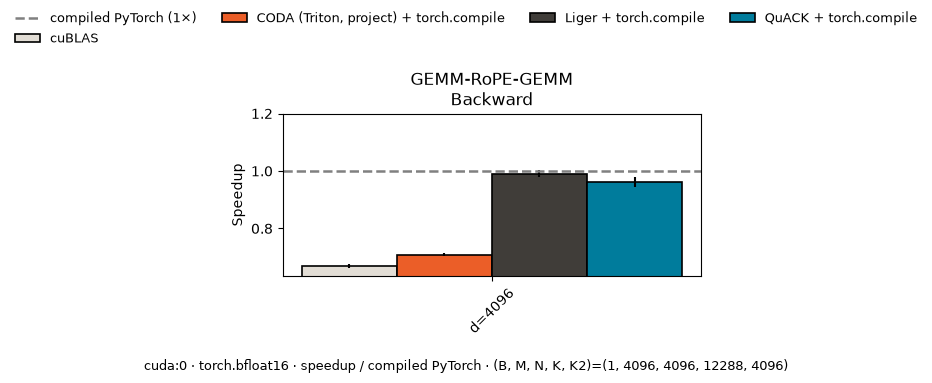

In [34]:
experiment('rope', (1, 4096, 4096, 12288, 4096), 'bwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,6.1 ± 0.07,0.65×
cuBLAS + torch.compile,3.9 ± 0.03,1.00×
"CODA (Triton, project) + torch.compile",6.4 ± 0.04,0.61×
Liger + torch.compile,4.2 ± 0.2,0.94×
QuACK + torch.compile,4.2 ± 0.08,0.94×


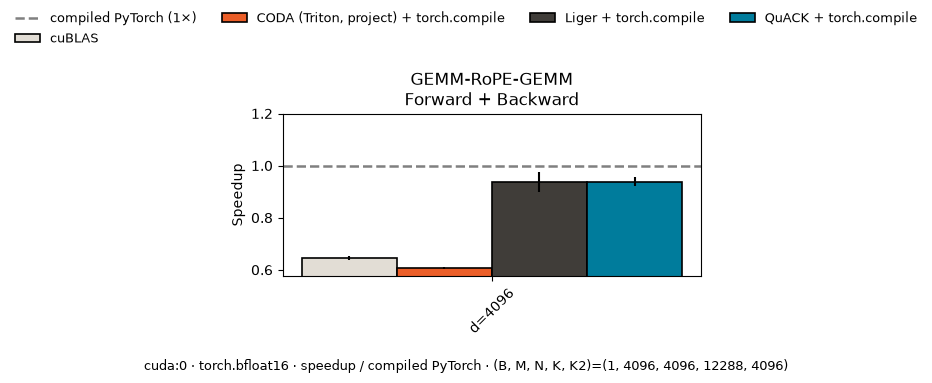

In [35]:
experiment('rope', (1, 4096, 4096, 12288, 4096), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,13 ± 0.2,0.76×
cuBLAS + torch.compile,10 ± 0.06,1.00×
"CODA (Triton, project) + torch.compile",21 ± 1,0.48×
Liger + torch.compile,10 ± 0.07,0.98×
FlashInfer,10 ± 0.2,1.01×
QuACK + torch.compile,9.9 ± 0.1,1.01×


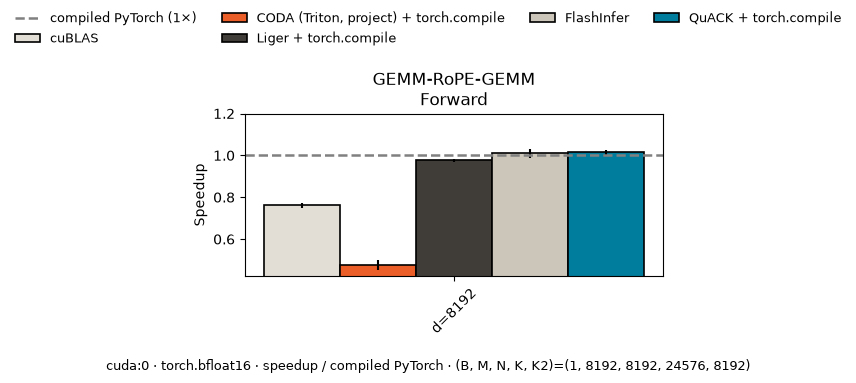

In [36]:
experiment('rope', (1, 8192, 8192, 24576, 8192), 'fwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,25 ± 0.8,0.81×
cuBLAS + torch.compile,20 ± 0.8,1.00×
"CODA (Triton, project) + torch.compile",27 ± 1,0.76×
Liger + torch.compile,20 ± 0.7,0.99×
QuACK + torch.compile,20 ± 0.9,1.01×


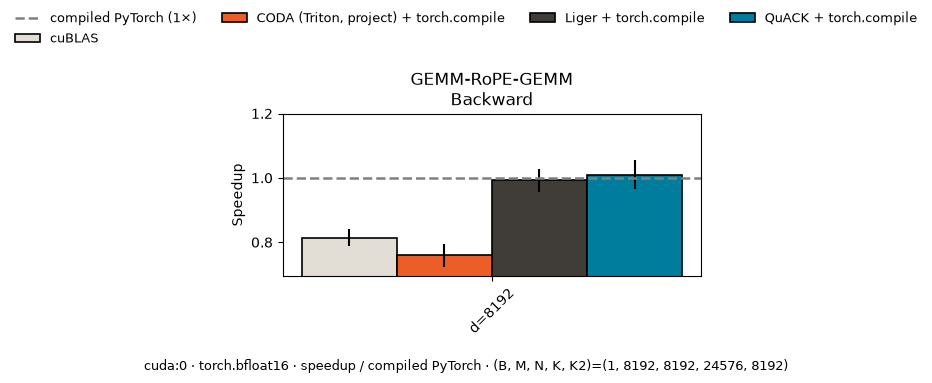

In [37]:
experiment('rope', (1, 8192, 8192, 24576, 8192), 'bwd', device='cuda', dtype=torch.bfloat16)

FlashInfer: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,39 ± 1,0.79×
cuBLAS + torch.compile,31 ± 0.6,1.00×
"CODA (Triton, project) + torch.compile",48 ± 0.8,0.64×
Liger + torch.compile,31 ± 0.4,0.98×
QuACK + torch.compile,30 ± 0.5,1.01×


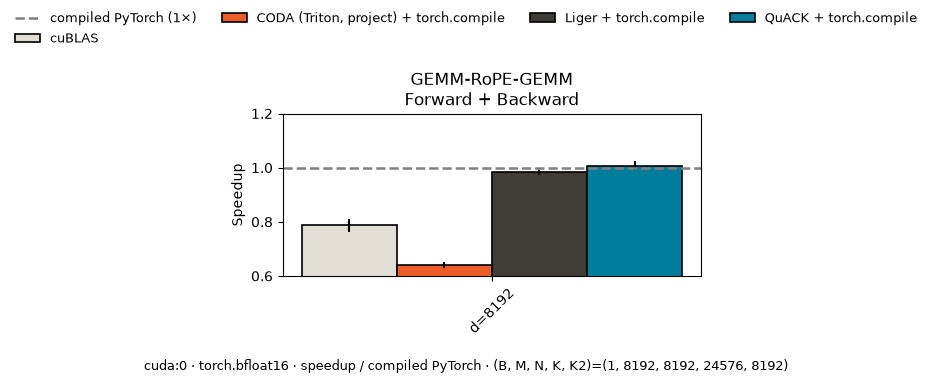

In [38]:
experiment('rope', (1, 8192, 8192, 24576, 8192), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

### GEMM + cross entropy

Liger: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,41 ± 0.03,0.04×
cuBLAS + torch.compile,1.7 ± 0.08,1.00×
"CODA (Triton, project) + torch.compile",5.7 ± 0.06,0.31×
Liger,2.2 ± 0.02,0.80×
Liger fused CE + torch.compile,2 ± 0.03,0.87×
QuACK + torch.compile,1.8 ± 0.06,0.98×


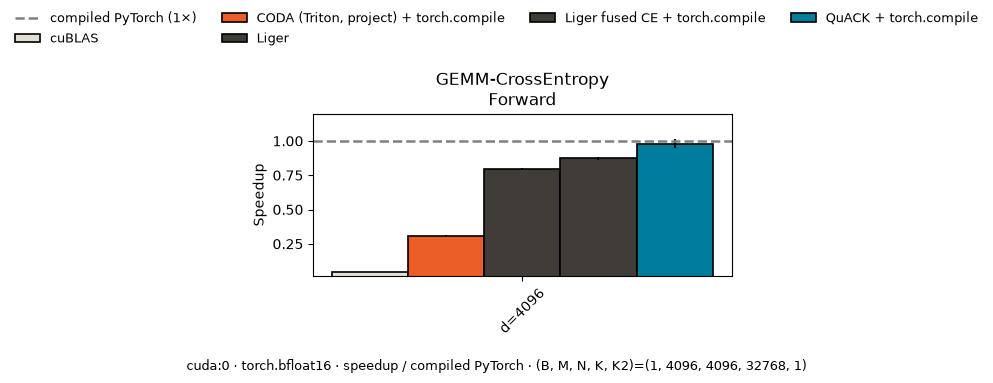

In [39]:
experiment('ce', (1, 4096, 4096, 32768, 1), 'fwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,21 ± 0.04,0.18×
cuBLAS + torch.compile,3.8 ± 0.08,1.00×
"CODA (Triton, project) + torch.compile",3.5 ± 0.06,1.09×
Liger,3.7 ± 0.04,1.02×
QuACK + torch.compile,3.4 ± 0.05,1.12×


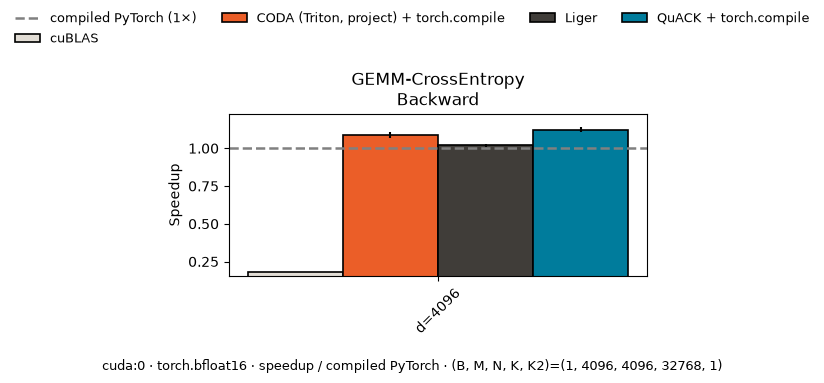

In [40]:
experiment('ce', (1, 4096, 4096, 32768, 1), 'bwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in fwd+bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,61 ± 0.04,0.09×
cuBLAS + torch.compile,5.5 ± 0.07,1.00×
"CODA (Triton, project) + torch.compile",9 ± 0.04,0.61×
Liger,6.1 ± 0.09,0.90×
QuACK + torch.compile,5.4 ± 0.1,1.03×


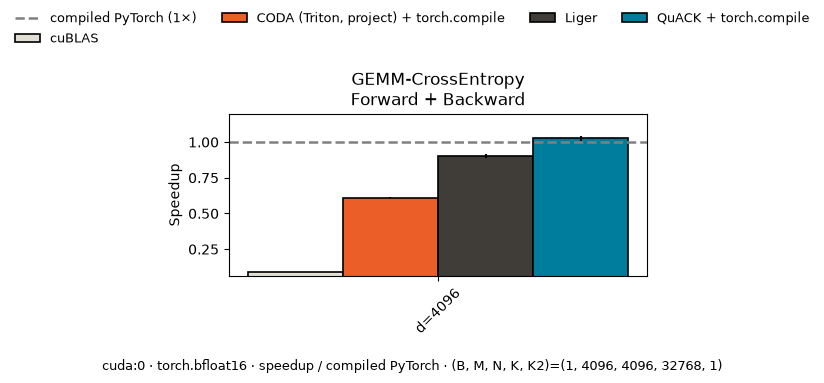

In [41]:
experiment('ce', (1, 4096, 4096, 32768, 1), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in fwd; measuring eager


implementation,ms,speedup_compile
cuBLAS,47 ± 0.02,0.15×
cuBLAS + torch.compile,6.9 ± 0.09,1.00×
"CODA (Triton, project) + torch.compile",23 ± 0.06,0.31×
Liger,7.8 ± 0.09,0.88×
Liger fused CE + torch.compile,7.1 ± 0.07,0.97×
QuACK + torch.compile,6.7 ± 0.1,1.03×


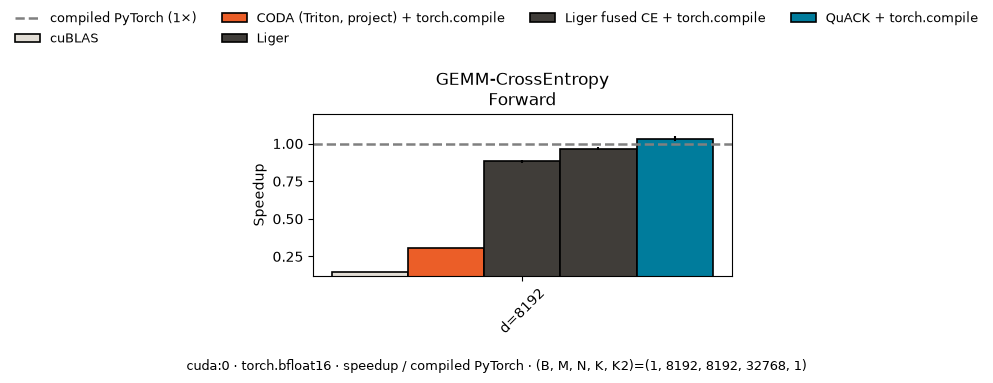

In [42]:
experiment('ce', (1, 8192, 8192, 32768, 1), 'fwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,31 ± 0.1,0.45×
cuBLAS + torch.compile,14 ± 0.3,1.00×
"CODA (Triton, project) + torch.compile",13 ± 0.7,1.04×
Liger,14 ± 0.5,0.96×
QuACK + torch.compile,13 ± 0.2,1.06×


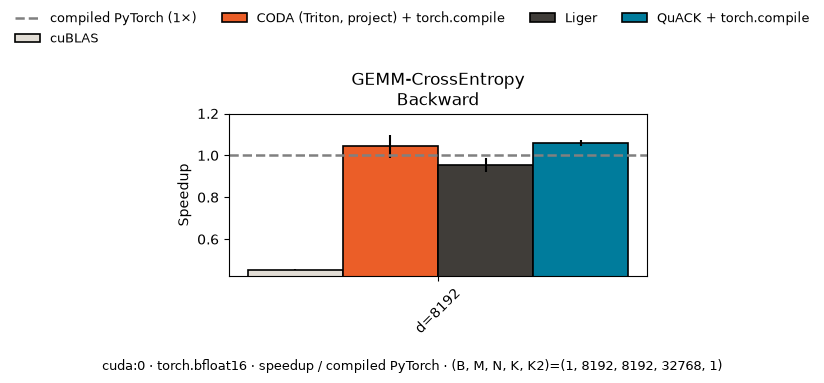

In [43]:
experiment('ce', (1, 8192, 8192, 32768, 1), 'bwd', device='cuda', dtype=torch.bfloat16)

Liger: torch.compile unavailable in fwd+bwd; measuring eager
Liger fused CE: NotImplementedError: Forward only


implementation,ms,speedup_compile
cuBLAS,78 ± 0.5,0.26×
cuBLAS + torch.compile,20 ± 0.6,1.00×
"CODA (Triton, project) + torch.compile",36 ± 0.6,0.57×
Liger,23 ± 0.6,0.89×
QuACK + torch.compile,20 ± 0.4,1.02×


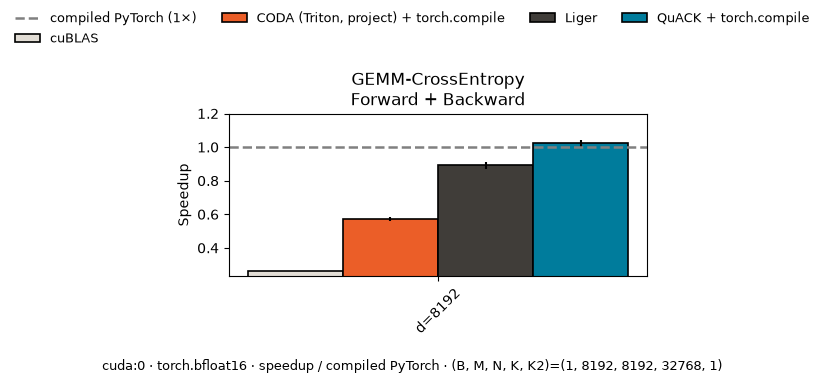

In [44]:
experiment('ce', (1, 8192, 8192, 32768, 1), 'fwd+bwd', device='cuda', dtype=torch.bfloat16)

## Block speedups · Figure 11

In [45]:
from ast import literal_eval
target = pd.concat(results, ignore_index=True)
target = target[(target.device == 'cuda') & (target.dtype == 'torch.bfloat16') &
                target['shape'].map(lambda shape: literal_eval(shape)[1] >= 4096)]
plot_speedups(target)

## Perfetto

In [46]:
if TRACE:
    experiment('rms', (2, 35, 19, 38, 17), 'fwd+bwd', device='cuda',
               names=('cuBLAS', 'cuBLAS + torch.compile', 'CODA (Triton, project)'), trace_dir='results/traces')

## CSV

In [47]:
folder = Path('results')
folder.mkdir(exist_ok=True)
path = folder / f"bench_{datetime.now():%Y%m%d_%H%M%S}.csv"
saved = pd.concat(results, ignore_index=True)
columns = ['task', 'shape', 'mode', 'device', 'dtype', 'implementation', 'mean_ms', 'std_ms',
           'speedup_compile', 'tiles', 'eps', 'packages', 'threads', 'hardware', 'status', 'reason']
if 'compile_fallback' in saved:
    columns.append('compile_fallback')
saved.reindex(columns=columns).to_csv(path, index=False, float_format='%.6g')
print(path)


results/bench_20261010_192137.csv
